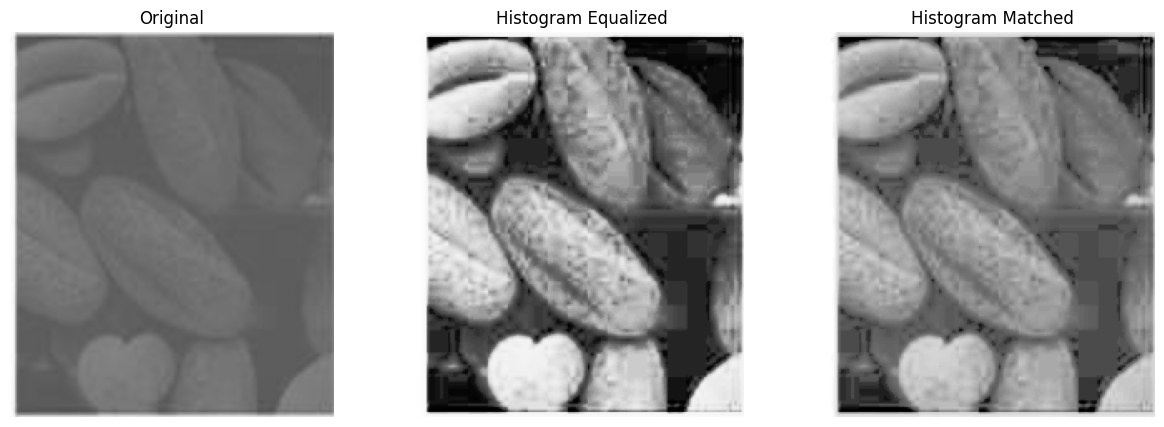

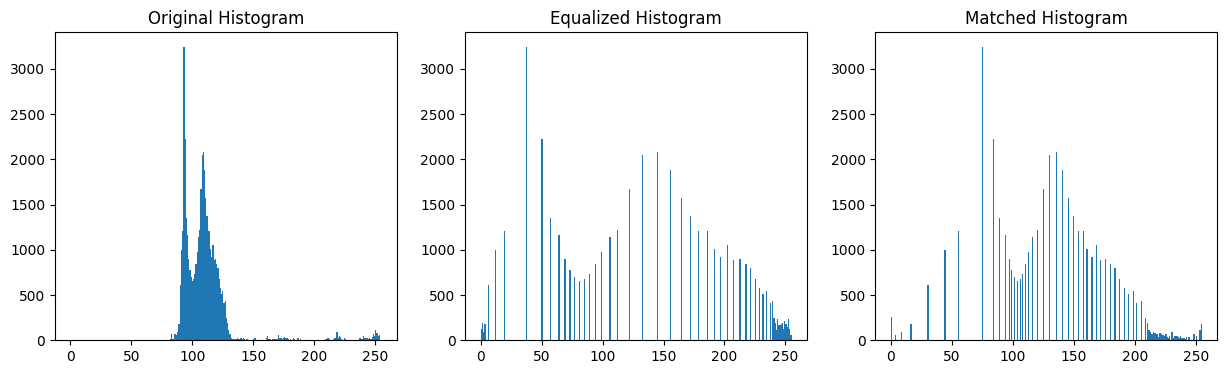

Original : mean=110.6  std=23.8
Equalized: mean=130.7  std=72.5
Matched  : mean=129.8  std=48.2


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

src_image = plt.imread("ex1_1.png")
if src_image.ndim == 3:
    src_image = np.dot(src_image[..., :3], [0.2989, 0.5870, 0.1140])

if src_image.max() <= 1.0:
    src_image = src_image * 255

src_image = src_image.astype(np.uint8)

# -------------------------
# Histogram Equalization
# -------------------------
hist, bins = np.histogram(src_image.flatten(), 256, [0, 256])
cdf = hist.cumsum()
cdf_normalized = (cdf - cdf.min()) * 255 / (cdf.max() - cdf.min())
cdf_normalized = cdf_normalized.astype(np.uint8)
equalized_image = cdf_normalized[src_image]

# -------------------------
# Reference image (Gaussian target, mean=128, std=50)
# -------------------------
np.random.seed(42)
reference_image = np.random.normal(loc=128, scale=50, size=(300, 300))
reference_image = np.clip(reference_image, 0, 255).astype(np.uint8)

# -------------------------
# Histogram Matching (manual, using pandas for CDF lookup)
# -------------------------
src_hist, _ = np.histogram(src_image.flatten(), 256, [0, 256])
ref_hist, _ = np.histogram(reference_image.flatten(), 256, [0, 256])

src_cdf = np.cumsum(src_hist).astype(np.float64)
src_cdf = src_cdf / src_cdf[-1]

ref_cdf = np.cumsum(ref_hist).astype(np.float64)
ref_cdf = ref_cdf / ref_cdf[-1]

mapping = pd.Series(index=np.arange(256), dtype=np.uint8)
ref_cdf_series = pd.Series(ref_cdf)

for i in range(256):
    diff = (ref_cdf_series - src_cdf[i]).abs()
    mapping[i] = diff.idxmin()

mapping = mapping.values.astype(np.uint8)
matched_image = mapping[src_image]

# -------------------------
# Display Images
# -------------------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(src_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalized")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(matched_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Matched")
plt.axis('off')

plt.show()

# -------------------------
# Histograms
# -------------------------
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(src_image.ravel(), bins=256, range=(0, 255))
plt.title("Original Histogram")

plt.subplot(1, 3, 2)
plt.hist(equalized_image.ravel(), bins=256, range=(0, 255))
plt.title("Equalized Histogram")

plt.subplot(1, 3, 3)
plt.hist(matched_image.ravel(), bins=256, range=(0, 255))
plt.title("Matched Histogram")

plt.show()

print(f"Original : mean={src_image.mean():.1f}  std={src_image.std():.1f}")
print(f"Equalized: mean={equalized_image.mean():.1f}  std={equalized_image.std():.1f}")
print(f"Matched  : mean={matched_image.mean():.1f}  std={matched_image.std():.1f}")

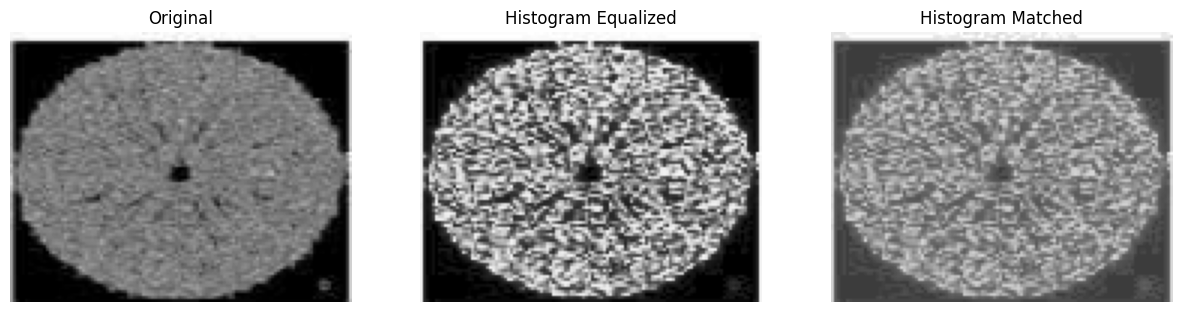

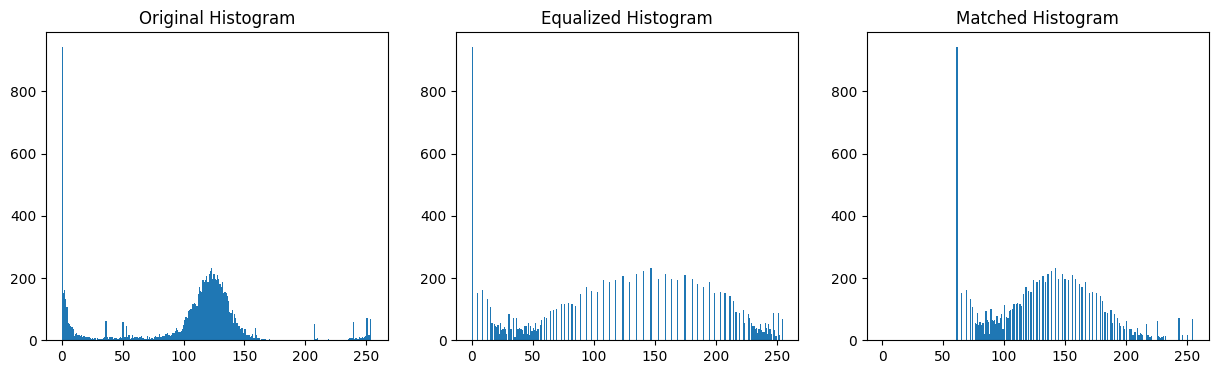

Original : mean=101.1  std=57.0
Equalized: mean=116.9  std=79.5
Matched  : mean=130.2  std=46.1


In [8]:
src_image = plt.imread("ex1_2.png")
if src_image.ndim == 3:
    src_image = np.dot(src_image[..., :3], [0.2989, 0.5870, 0.1140])

if src_image.max() <= 1.0:
    src_image = src_image * 255

src_image = src_image.astype(np.uint8)

hist, bins = np.histogram(src_image.flatten(), 256, [0, 256])
cdf = hist.cumsum()
cdf_normalized = (cdf - cdf.min()) * 255 / (cdf.max() - cdf.min())
cdf_normalized = cdf_normalized.astype(np.uint8)
equalized_image = cdf_normalized[src_image]

np.random.seed(42)
reference_image = np.random.normal(loc=128, scale=50, size=(300, 300))
reference_image = np.clip(reference_image, 0, 255).astype(np.uint8)

src_hist, _ = np.histogram(src_image.flatten(), 256, [0, 256])
ref_hist, _ = np.histogram(reference_image.flatten(), 256, [0, 256])

src_cdf = np.cumsum(src_hist).astype(np.float64)
src_cdf = src_cdf / src_cdf[-1]

ref_cdf = np.cumsum(ref_hist).astype(np.float64)
ref_cdf = ref_cdf / ref_cdf[-1]

mapping = pd.Series(index=np.arange(256), dtype=np.uint8)
ref_cdf_series = pd.Series(ref_cdf)

for i in range(256):
    diff = (ref_cdf_series - src_cdf[i]).abs()
    mapping[i] = diff.idxmin()

mapping = mapping.values.astype(np.uint8)
matched_image = mapping[src_image]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(src_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalized")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(matched_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Matched")
plt.axis('off')

plt.show()

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(src_image.ravel(), bins=256, range=(0, 255))
plt.title("Original Histogram")

plt.subplot(1, 3, 2)
plt.hist(equalized_image.ravel(), bins=256, range=(0, 255))
plt.title("Equalized Histogram")

plt.subplot(1, 3, 3)
plt.hist(matched_image.ravel(), bins=256, range=(0, 255))
plt.title("Matched Histogram")

plt.show()

print(f"Original : mean={src_image.mean():.1f}  std={src_image.std():.1f}")
print(f"Equalized: mean={equalized_image.mean():.1f}  std={equalized_image.std():.1f}")
print(f"Matched  : mean={matched_image.mean():.1f}  std={matched_image.std():.1f}")

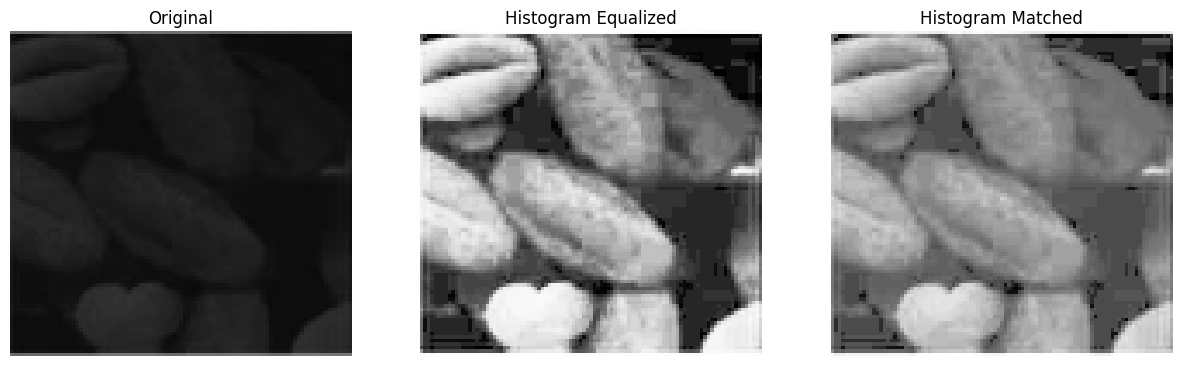

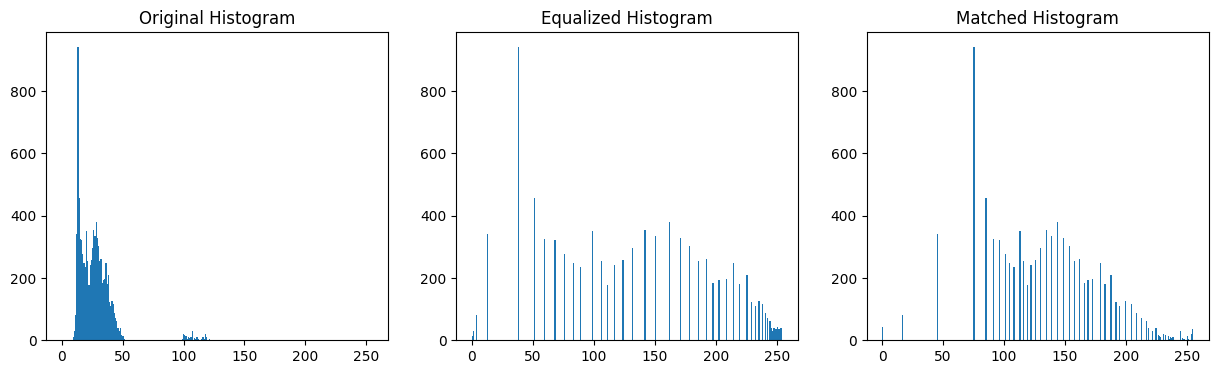

Original : mean=26.5  std=15.4
Equalized: mean=131.6  std=71.6
Matched  : mean=130.8  std=47.2


In [9]:
src_image = plt.imread("ex1_3.png")
if src_image.ndim == 3:
    src_image = np.dot(src_image[..., :3], [0.2989, 0.5870, 0.1140])

if src_image.max() <= 1.0:
    src_image = src_image * 255

src_image = src_image.astype(np.uint8)

hist, bins = np.histogram(src_image.flatten(), 256, [0, 256])
cdf = hist.cumsum()
cdf_normalized = (cdf - cdf.min()) * 255 / (cdf.max() - cdf.min())
cdf_normalized = cdf_normalized.astype(np.uint8)
equalized_image = cdf_normalized[src_image]

np.random.seed(42)
reference_image = np.random.normal(loc=128, scale=50, size=(300, 300))
reference_image = np.clip(reference_image, 0, 255).astype(np.uint8)

src_hist, _ = np.histogram(src_image.flatten(), 256, [0, 256])
ref_hist, _ = np.histogram(reference_image.flatten(), 256, [0, 256])

src_cdf = np.cumsum(src_hist).astype(np.float64)
src_cdf = src_cdf / src_cdf[-1]

ref_cdf = np.cumsum(ref_hist).astype(np.float64)
ref_cdf = ref_cdf / ref_cdf[-1]

mapping = pd.Series(index=np.arange(256), dtype=np.uint8)
ref_cdf_series = pd.Series(ref_cdf)

for i in range(256):
    diff = (ref_cdf_series - src_cdf[i]).abs()
    mapping[i] = diff.idxmin()

mapping = mapping.values.astype(np.uint8)
matched_image = mapping[src_image]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(src_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalized")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(matched_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Matched")
plt.axis('off')

plt.show()

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(src_image.ravel(), bins=256, range=(0, 255))
plt.title("Original Histogram")

plt.subplot(1, 3, 2)
plt.hist(equalized_image.ravel(), bins=256, range=(0, 255))
plt.title("Equalized Histogram")

plt.subplot(1, 3, 3)
plt.hist(matched_image.ravel(), bins=256, range=(0, 255))
plt.title("Matched Histogram")

plt.show()

print(f"Original : mean={src_image.mean():.1f}  std={src_image.std():.1f}")
print(f"Equalized: mean={equalized_image.mean():.1f}  std={equalized_image.std():.1f}")
print(f"Matched  : mean={matched_image.mean():.1f}  std={matched_image.std():.1f}")

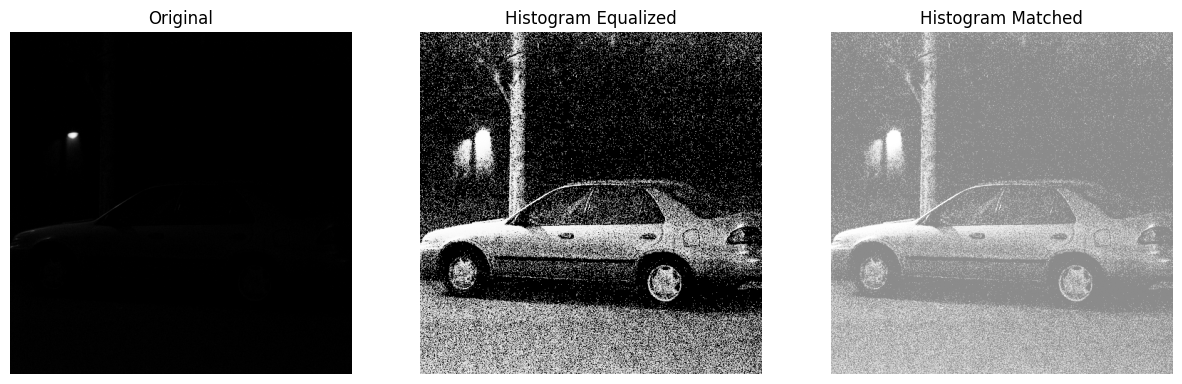

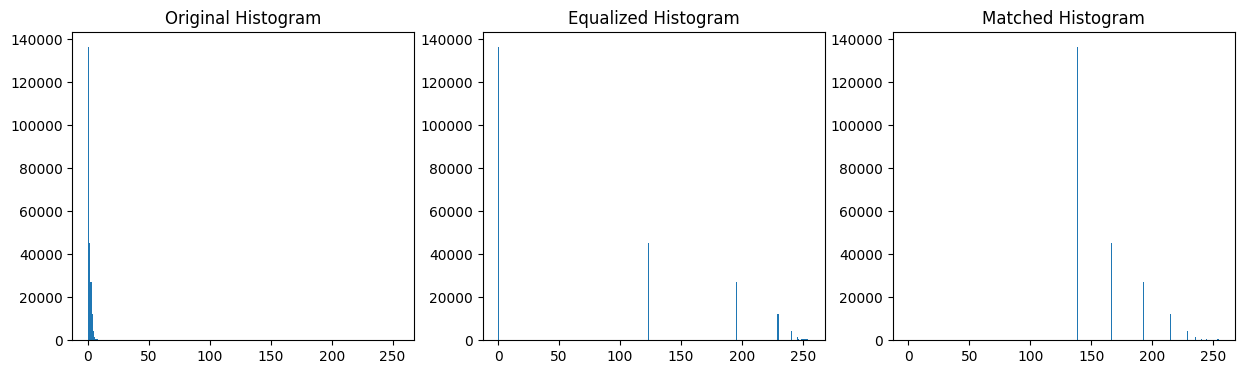

Original : mean=1.0  std=4.8
Equalized: mean=69.3  std=89.0
Matched  : mean=158.8  std=28.3


In [10]:
src_image = plt.imread("ex1_4.png")
if src_image.ndim == 3:
    src_image = np.dot(src_image[..., :3], [0.2989, 0.5870, 0.1140])

if src_image.max() <= 1.0:
    src_image = src_image * 255

src_image = src_image.astype(np.uint8)

hist, bins = np.histogram(src_image.flatten(), 256, [0, 256])
cdf = hist.cumsum()
cdf_normalized = (cdf - cdf.min()) * 255 / (cdf.max() - cdf.min())
cdf_normalized = cdf_normalized.astype(np.uint8)
equalized_image = cdf_normalized[src_image]

np.random.seed(42)
reference_image = np.random.normal(loc=128, scale=50, size=(300, 300))
reference_image = np.clip(reference_image, 0, 255).astype(np.uint8)

src_hist, _ = np.histogram(src_image.flatten(), 256, [0, 256])
ref_hist, _ = np.histogram(reference_image.flatten(), 256, [0, 256])

src_cdf = np.cumsum(src_hist).astype(np.float64)
src_cdf = src_cdf / src_cdf[-1]

ref_cdf = np.cumsum(ref_hist).astype(np.float64)
ref_cdf = ref_cdf / ref_cdf[-1]

mapping = pd.Series(index=np.arange(256), dtype=np.uint8)
ref_cdf_series = pd.Series(ref_cdf)

for i in range(256):
    diff = (ref_cdf_series - src_cdf[i]).abs()
    mapping[i] = diff.idxmin()

mapping = mapping.values.astype(np.uint8)
matched_image = mapping[src_image]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(src_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalized")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(matched_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Matched")
plt.axis('off')

plt.show()

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(src_image.ravel(), bins=256, range=(0, 255))
plt.title("Original Histogram")

plt.subplot(1, 3, 2)
plt.hist(equalized_image.ravel(), bins=256, range=(0, 255))
plt.title("Equalized Histogram")

plt.subplot(1, 3, 3)
plt.hist(matched_image.ravel(), bins=256, range=(0, 255))
plt.title("Matched Histogram")

plt.show()

print(f"Original : mean={src_image.mean():.1f}  std={src_image.std():.1f}")
print(f"Equalized: mean={equalized_image.mean():.1f}  std={equalized_image.std():.1f}")
print(f"Matched  : mean={matched_image.mean():.1f}  std={matched_image.std():.1f}")

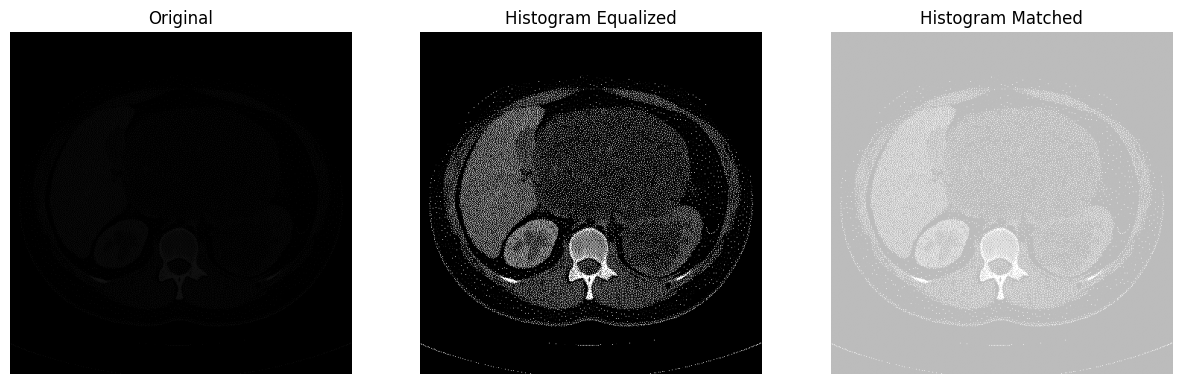

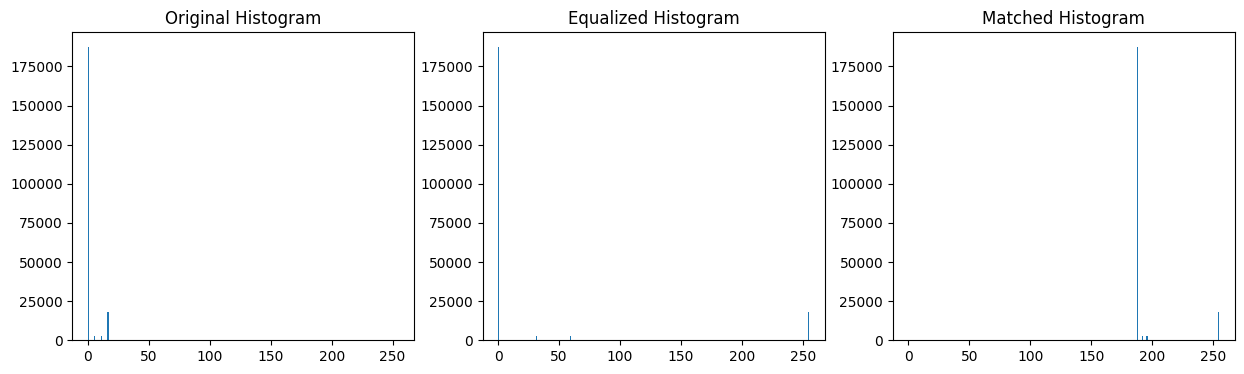

Original : mean=1.6  std=4.6
Equalized: mean=22.7  std=70.9
Matched  : mean=193.8  std=18.6


In [11]:
src_image = plt.imread("ex1_5.png")
if src_image.ndim == 3:
    src_image = np.dot(src_image[..., :3], [0.2989, 0.5870, 0.1140])

if src_image.max() <= 1.0:
    src_image = src_image * 255

src_image = src_image.astype(np.uint8)

hist, bins = np.histogram(src_image.flatten(), 256, [0, 256])
cdf = hist.cumsum()
cdf_normalized = (cdf - cdf.min()) * 255 / (cdf.max() - cdf.min())
cdf_normalized = cdf_normalized.astype(np.uint8)
equalized_image = cdf_normalized[src_image]

np.random.seed(42)
reference_image = np.random.normal(loc=128, scale=50, size=(300, 300))
reference_image = np.clip(reference_image, 0, 255).astype(np.uint8)

src_hist, _ = np.histogram(src_image.flatten(), 256, [0, 256])
ref_hist, _ = np.histogram(reference_image.flatten(), 256, [0, 256])

src_cdf = np.cumsum(src_hist).astype(np.float64)
src_cdf = src_cdf / src_cdf[-1]

ref_cdf = np.cumsum(ref_hist).astype(np.float64)
ref_cdf = ref_cdf / ref_cdf[-1]

mapping = pd.Series(index=np.arange(256), dtype=np.uint8)
ref_cdf_series = pd.Series(ref_cdf)

for i in range(256):
    diff = (ref_cdf_series - src_cdf[i]).abs()
    mapping[i] = diff.idxmin()

mapping = mapping.values.astype(np.uint8)
matched_image = mapping[src_image]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(src_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalized")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(matched_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Matched")
plt.axis('off')

plt.show()

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(src_image.ravel(), bins=256, range=(0, 255))
plt.title("Original Histogram")

plt.subplot(1, 3, 2)
plt.hist(equalized_image.ravel(), bins=256, range=(0, 255))
plt.title("Equalized Histogram")

plt.subplot(1, 3, 3)
plt.hist(matched_image.ravel(), bins=256, range=(0, 255))
plt.title("Matched Histogram")

plt.show()

print(f"Original : mean={src_image.mean():.1f}  std={src_image.std():.1f}")
print(f"Equalized: mean={equalized_image.mean():.1f}  std={equalized_image.std():.1f}")
print(f"Matched  : mean={matched_image.mean():.1f}  std={matched_image.std():.1f}")